## ledger_v2 × MCP alignment

Loads `data/corpus/ledger_v2.csv`. Document-level MCP fields are scalars; per-chunk fields are JSON lists (one entry per chunk, chunk order) and are parsed into Python lists below.
`mcp_status`: `matched` | `matched_ambiguous` (same file name under several dates, closest to CreationDate chosen) | `undetermined`.

In [ ]:
import csv, json
from pathlib import Path
import pandas as pd
import re

csv.field_size_limit(2**30)  # some list cells exceed 128 KB
pd.set_option('display.max_colwidth', 80, 'display.width', 200, 'display.max_columns', 40)

# LEDGER = Path('.') / 'data' / 'corpus' / 'ledger_v2.csv'
# LIST_COLS = ['mcp_chunk_ids', 'Author_MCP', 'AuthorRole', 'Conviction', 'Sentiment', 'ResearchDepth',
#              'SignalQuality', 'DataQuality', 'MacroTheme', 'RegionCountry', 'Asset', 'Catalyst', 'Keywords']

# df = pd.read_csv(LEDGER, encoding='utf-8-sig', engine='python', dtype=str, keep_default_na=False)
# for c in LIST_COLS:
#     df[c] = df[c].map(lambda s: json.loads(s) if s else None)
# df['mcp_n_chunks'] = pd.to_numeric(df['mcp_n_chunks'], errors='coerce').astype('Int64')
# df['created_at'] = pd.to_datetime(df['CreationDate'].str.extract(r'D:(\d{8})')[0], format='%Y%m%d')
# df['doc_date'] = pd.to_datetime(df['DocumentDate'], errors='coerce')
# print(df.shape)
# df.head(2)

(10682, 26)


,file_path,file_name,CreationDate,Title,mcp_status,mcp_note,mcp_n_chunks,mcp_chunk_ids,Author_MCP,Source,DocumentDate,DocumentType,TradeIdeaFlag,AuthorRole,Conviction,Sentiment,ResearchDepth,SignalQuality,DataQuality,MacroTheme,RegionCountry,Asset,Catalyst,Keywords,created_at,doc_date
0,bnp/2025_EUR_government_bond_and_SSA_issuance_outlook_Desknote--850446.pdf,2025_EUR_government_bond_and_SSA_issuance_outlook_Desknote--850446.pdf,D:20250116120322Z,20250114_Focus_EURIssuance2025.pptx,matched,,18,"[2025_EUR_government_bond_and_SSA_issuance_outlook_Desknote--850446.pdf-1-0,...","[Anubhav Lamichhane; Katherine Yoon, Anubhav Lamichhane; Katherine Yoon, Anu...",BNP Paribas,2025-01-16,Outlook,False,"[Strategist, Strategist, Strategist, Strategist, Strategist, Strategist, Str...","[Medium, Medium, Low, Medium, Medium, Medium, Medium, Medium, Medium, Medium...","[Bearish, Bearish, Neutral, Neutral, Neutral, Mixed, Neutral, Neutral, Neutr...","[Standard, Standard, Quick Take, Standard, Standard, Standard, Quick Take, S...","[High, High, Low, High, High, High, Medium, High, High, High, High, Low, Hig...","[High, High, Low, High, Medium, High, Medium, High, High, High, High, Low, H...","[Liquidity, Liquidity, Other, Liquidity, Liquidity, Policy, Liquidity, Liqui...","[{'Country': 'EU', 'Region': 'EMEA'}, {'Country': None, 'Region': 'EMEA'}, {...","[{'Ticker': None, 'Class': 'Rates', 'SubClass': 'EUR government bonds / EGBs...","[{'Phase': 'Preview', 'Date': '2025-01-16', 'Entity': 'Euro area governments...","[[net supply, quantitative tightening, PEPP reinvestments, term premia, curv...",2025-01-16,2025-01-16
1,bnp/2025_US_Economic_Calendar_Presentation--846837.pdf,2025_US_Economic_Calendar_Presentation--846837.pdf,D:20241213074114-05'00',20241205_2025 US calendar.pptx,undetermined,no MCP chunks with this file name in fetched windows (e.g. empty DocumentDate),<NA>,None,None,,,,,None,None,None,None,None,None,None,None,None,None,None,2024-12-13,NaT


In [2]:
def flat_set(v, key=None, split=False):
    """Per-chunk list -> sorted list of distinct non-null values.
    key:   pick one sub-field of dict entries (Asset, Catalyst, RegionCountry).
    split: also break packed strings ('IN; MX', 'US/NO/SE', 'ID,BR,CO') into separate upper-case codes.
           Use for Country/Region only; it would break phrases in Keywords."""
    out, stack = set(), list(v) if v else []
    while stack:
        x = stack.pop()
        if x in (None, '', []):
            continue
        if isinstance(x, list):
            stack.extend(x)
        elif isinstance(x, dict):
            if key:
                stack.append(x.get(key))
            else:
                out.add(json.dumps({k: val for k, val in x.items() if val}, sort_keys=True))
        elif split:
            out.update(t.upper() for t in re.split(r'[,;/|&\s]+|\band\b', str(x)) if t)
        else:
            out.add(x)
    return sorted(out, key=str)

In [ ]:
# Author_pdf vs Author_MCP: pdf author is the PowerPoint/PDF creator, MCP author is extracted from the text
def mcp_names(v):
    out = set()
    for a in (v or []):
        if isinstance(a, list):
            out |= {x.get('Name') for x in a if isinstance(x, dict) and x.get('Name')}
        elif isinstance(a, str) and a:
            out |= {n.strip() for n in a.split(';') if n.strip()}
    return sorted(out)

df['mcp_authors'] = df['Author_MCP'].map(mcp_names)
df['pdf_in_mcp'] = [bool(p) and any(p.lower() in n.lower() or n.lower() in p.lower() for n in names)
                    for p, names in zip(df['Author_pdf'], df['mcp_authors'])]
print(df[df['mcp_status'] != 'undetermined'].groupby('folder')['pdf_in_mcp'].mean())
df[df['mcp_status'] != 'undetermined'][['file_name', 'Author_pdf', 'mcp_authors']].sample(8, random_state=0)

In [3]:
# drop void columns (Conviction, ResearchDepth, SignalQuality, DataQuality)
df = df.drop(columns=['Conviction', 'ResearchDepth', 'SignalQuality', 'DataQuality'], errors='ignore')

In [4]:
# scalar-per-chunk columns
cols = ['Sentiment', 'MacroTheme', 'Keywords']
raw = df[cols].copy()                  # per-chunk originals, for chunks() etc.
for c in cols:
    df[c] = df[c].map(flat_set)

In [5]:
df['Sentiment'].value_counts(dropna=False).head(2)   # documents containing each value

Sentiment
[Bearish, Bullish, Mixed, Neutral]    3397
[Bearish, Mixed, Neutral]             2382
Name: count, dtype: int64

In [6]:
# dict-per-chunk columns: pick the sub-field you want
df['AssetTicker']  = df['Asset'].map(lambda v: flat_set(v, 'Ticker'))
df['AssetClass']   = df['Asset'].map(lambda v: flat_set(v, 'Class'))
df['AssetSubClass']   = df['Asset'].map(lambda v: flat_set(v, 'SubClass'))
df = df.drop(columns=['Asset'])


In [7]:
df['AssetClass'].value_counts(dropna=False).head(2)  # documents containing each value

AssetClass
[Rates]        2486
[FX, Rates]     970
Name: count, dtype: int64

In [8]:
df['Region'] = df['RegionCountry'].map(lambda v: flat_set(v, 'Region'))
df['Country'] = df['RegionCountry'].map(lambda v: flat_set(v, 'Country', split=True))
df = df.drop(columns=['RegionCountry'])

In [9]:
df['Country'].value_counts(dropna=False).tail(2)

Country
[AU, CH, JP]            1
[CH, GB, JP, NZ, US]    1
Name: count, dtype: int64

In [10]:
import sys; sys.path.insert(0, './scripts')
from author_names import author_records, distinct_names
from haiku_name_check import check_names

import inspect, haiku_name_check
print('_generate' in dir(haiku_name_check))     # True once the new code is loaded

True


In [11]:
# df['Author'] = [author_records(a, r, broadcast=True) for a, r in zip(df.Author_MCP, df.AuthorRole)]

# optional second opinion from Haiku on the distinct names the rules keep
verdicts = check_names(distinct_names(df.Author_MCP, df.AuthorRole, broadcast=True))
people = {n for n, v in verdicts.items() if v == 'person'}
df['Author'] = [author_records(a, r, broadcast=True, keep=people) for a, r in zip(df.Author_MCP, df.AuthorRole)]

checking names:   0%|          | 0/8 [00:00<?, ?name/s]

In [12]:
import pandas as pd

v = pd.Series(verdicts)
v[v != 'person'].sort_values()                 # everything Haiku said is not a person, with its label
v[v == 'team']                                 # just teams
v[v == 'other']                                # fragments and non-names
v[v == 'unchecked']                            # names the model dropped or altered, or a parse failure
v.value_counts()                               # how many of each


person    1977
team         3
Name: count, dtype: int64

In [13]:
from author_names import person_names
from collections import Counter

review = []
for chunks in df.Author_MCP:
    for a in (chunks or []):                       # None for undetermined rows
        for x in (a if isinstance(a, list) else [a]):
            s = x.get('Name') if isinstance(x, dict) else x
            if isinstance(s, str):
                person_names(s, review)

Counter(review).most_common(60)

[('with', 484),
 ('Morgan Stanley', 447),
 ('including', 403),
 ('of', 383),
 ('Cross', 273),
 ('the', 183),
 ('London', 151),
 ('Ryan', 66),
 ('Luzzetti', 66),
 ('Weidner', 66),
 ('Yang', 66),
 ('HY', 64),
 ('U S', 47),
 ('Aguirre', 43),
 ('Hong Kong', 39),
 ('GS', 35),
 ('Kevin', 24),
 ('AI', 16),
 ('Front-end', 11),
 ('Marshall', 9),
 ('Zu', 9),
 ('Talisman', 5),
 ('-', 3),
 ('Argentina', 3),
 ('Chile', 3),
 ('Colombia', 3)]

In [14]:
df['Author'].explode().value_counts().head(5)

Author
{'Name': 'Alex Jekov', 'Role': 'Strategist'}        365
{'Name': 'Arunima Sinha', 'Role': 'Economist'}      283
{'Name': 'Guanchen Xie', 'Role': 'Strategist'}      252
{'Name': 'Jonathan Pingle', 'Role': 'Economist'}    244
{'Name': 'Mario Castro', 'Role': 'Strategist'}      240
Name: count, dtype: int64

In [15]:
df = df.drop(columns=['Author_MCP', 'AuthorRole'])

In [16]:
df.columns

Index(['file_path', 'file_name', 'CreationDate', 'Title', 'mcp_status', 'mcp_note', 'mcp_n_chunks', 'mcp_chunk_ids', 'Source', 'DocumentDate', 'DocumentType', 'TradeIdeaFlag', 'Sentiment',
       'MacroTheme', 'Catalyst', 'Keywords', 'created_at', 'doc_date', 'AssetTicker', 'AssetClass', 'AssetSubClass', 'Region', 'Country', 'Author'],
      dtype='str')

In [17]:
path_cols = ['file_path', 'file_name']
provenance_cols = ['Source', 'Author', 'Title']
date_cols = ['CreationDate', 'DocumentDate', 'created_at', 'doc_date']
tagging_cols = ['Region', 'Country', 'MacroTheme', 'AssetClass', 'AssetSubClass', 'AssetTicker', 'Keywords', 'Sentiment', 'Catalyst', 'TradeIdeaFlag', 'DocumentType']
mcp_cols = [col for col in df.columns if col.startswith('mcp')]
df = df[path_cols + provenance_cols + date_cols + tagging_cols + mcp_cols]
df.columns


Index(['file_path', 'file_name', 'Source', 'Author', 'Title', 'CreationDate', 'DocumentDate', 'created_at', 'doc_date', 'Region', 'Country', 'MacroTheme', 'AssetClass', 'AssetSubClass',
       'AssetTicker', 'Keywords', 'Sentiment', 'Catalyst', 'TradeIdeaFlag', 'DocumentType', 'mcp_status', 'mcp_note', 'mcp_n_chunks', 'mcp_chunk_ids'],
      dtype='str')

In [28]:
from pathlib import Path

out = Path('.') / 'data' / 'corpus' / 'ledger_v3_matched.csv'    
import json
save = df.copy()
for c in save.columns:
    if save[c].map(lambda v: isinstance(v, (list, dict, set))).any():
        save[c] = save[c].map(lambda v: json.dumps(sorted(v) if isinstance(v, set) else v, ensure_ascii=False)
                              if isinstance(v, (list, dict, set)) else v)
save.to_csv(out, index=False, encoding='utf-8-sig')

In [19]:
# Alignment status by folder
pd.crosstab(df['file_path'].str.split('/').str[0].rename('folder'), df['mcp_status'], margins=True)

mcp_status,matched,matched_ambiguous,undetermined,All
folder,,,,
bnp,2515,0,159,2674
local,6479,388,125,6992
statestreet,710,0,306,1016
All,9704,388,590,10682


In [21]:
# Undetermined: reasons and month profile
und = df[df['mcp_status'] == 'undetermined']
print(und['mcp_note'].value_counts())
und.groupby(und['created_at'].dt.to_period('M')).size().rename('undetermined').tail(24)


mcp_note
no unique MCP title+date match in PDF pages 1-2                                   306
no MCP chunks with this file name in fetched windows (e.g. empty DocumentDate)    284
Name: count, dtype: int64


created_at
2024-11      5
2024-12      6
2025-01     18
2025-02     23
2025-03     20
2025-04     17
2025-05     38
2025-06     35
2025-07     41
2025-08     38
2025-09     46
2025-10    102
2025-11     36
2025-12     16
2026-01     17
2026-02     10
2026-03     18
2026-04     15
2026-05     20
2026-06     13
2026-07      8
2026-08      5
2026-09      8
2026-10     14
Freq: M, Name: undetermined, dtype: int64

In [22]:
# Sanity: gap between PDF CreationDate and MCP DocumentDate (matched only)
# helper: days between MCP DocumentDate and PDF creation date (kept out of df)
gap = (df['doc_date'] - df['created_at']).dt.days

# Sanity: gap between PDF CreationDate and MCP DocumentDate (matched only)
matched = df['mcp_status'] != 'undetermined'
print(gap[matched].describe())
(df[matched & (gap.abs() > 7)]
   .assign(date_gap_days=gap)                       # added to this view only, not to df
   [['file_name', 'created_at', 'doc_date', 'date_gap_days', 'mcp_status', 'mcp_note']]
   .sort_values('date_gap_days')
   .head(20))


count    10092.000000
mean         2.375941
std         40.866775
min       -164.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       1128.000000
dtype: float64


,file_name,created_at,doc_date,date_gap_days,mcp_status,mcp_note
2616,US_rates_Closing_long_bond_spreads_after_May_refunding_Trade_Idea--923516.pdf,2026-05-06,2025-11-23,-164.0,matched,
2617,US_rates_Closing_short_SFRZ6_Trade_Idea--922874.pdf,2026-04-24,2025-11-23,-152.0,matched,
2408,US_Equity_Flow_Insights_-_03_August_2025_Desknote--905532.pdf,2025-08-03,2025-03-18,-138.0,matched,
1377,India_s_FY2026_budget_A_nuanced_strategy_for_growth_Desknote--855686.pdf,2025-02-05,2024-09-30,-128.0,matched,
2618,US_rates_Closing_trades_Trade_Idea--919541.pdf,2026-02-27,2025-11-23,-96.0,matched,
4640,"BofA_US Economic Viewpoint - DOGE-bullish on efficiency, cautious on cost cu...",2025-04-28,2025-01-27,-91.0,matched,
184,Brazil_Mapping_out_consumption_support_in_2026_Desknote--914615.pdf,2025-12-09,2025-09-12,-88.0,matched,
5037,2025-03-01 BC_Japan Outlook - Impact on BoJ finances of a rate hike to 1per ...,2025-05-23,2025-03-01,-83.0,matched,
1845,Rates_Pay_Dec_RBA_versus_receive_Nov_FOMC_in_ratio_Trade_Idea--832590.pdf,2024-09-20,2024-07-02,-80.0,matched,
463,EGBs_Long_30y_BTP_vs_short_30y_DSL_Trade_Idea--902575.pdf,2025-09-02,2025-07-08,-56.0,matched,


In [24]:
# Ambiguous matches (several DocumentDates for one file name)
df[df['mcp_status'] == 'matched_ambiguous'][['file_name', 'created_at', 'doc_date', 'mcp_note']].head(10)

,file_name,created_at,doc_date,mcp_note
2701,UBS_European Economic Perspectives - European Central Bank Watch.pdf,2025-02-03,2025-02-03,"multiple dates for file name ['2025-02-03', '2025-11-03', '2025-12-01', '202..."
2728,MS_Morgan Stanley Research - Key Forecasts.pdf,2025-02-26,2025-02-25,"multiple dates for file name ['2025-01-27', '2025-02-25', '2025-03-24', '202..."
2738,DB_Commitment of Traders - Weekly Update.pdf,2025-01-02,2024-12-30,"multiple dates for file name ['2024-12-30', '2026-04-03', '2026-04-10', '202..."
2740,DB_US Economic Notes - What you need to know for the week ahead.pdf,2025-01-02,2025-01-03,"multiple dates for file name ['2024-12-29', '2025-01-03', '2025-01-12', '202..."
2753,DB_US Economic Notes - What you need to know for the week ahead.pdf,2025-01-03,2025-01-03,"multiple dates for file name ['2024-12-29', '2025-01-03', '2025-01-12', '202..."
2784,MS_Global Economic Briefing - The Global 360.pdf,2025-01-07,2026-06-22,"multiple dates for file name ['2026-06-22', '2026-10-26']; chose 2026-06-22 ..."
2834,DB_Cross-Discipline - Thematic Research - Next week...this week.pdf,2026-01-09,2026-01-09,"multiple dates for file name ['2025-11-07', '2025-11-14', '2026-01-09', '202..."
2843,"JPM_Global Fixed Income Markets Weekly - New year, renewed focus on carry.pdf",2026-01-09,2026-01-09,"multiple dates for file name ['2026-01-09', '2026-01-10']; chose 2026-01-09 ..."
2905,DB_US Economic Notes - What you need to know for the week ahead.pdf,2025-01-13,2025-01-12,"multiple dates for file name ['2024-12-29', '2025-01-03', '2025-01-12', '202..."
2917,UBS_Global Economics & Strategy - Core Convictions (Multi-Asset Rundown).pdf,2025-01-13,2025-01-13,"multiple dates for file name ['2025-01-13', '2025-01-27', '2025-02-10', '202..."


In [ ]:
# # Helper: explode a per-chunk list column to one row per chunk
# def chunks(cols=('Sentiment', 'Conviction', 'Keywords')):
#     cols = list(cols)
#     d = df[df['mcp_status'] != 'undetermined'][['file_path', 'DocumentDate', 'Source', 'mcp_chunk_ids'] + cols]
#     return d.explode(['mcp_chunk_ids'] + cols, ignore_index=True)

# ch = chunks()
# print(len(ch), 'chunks')
# ch['Sentiment'].value_counts(dropna=False)

In [26]:
# Free-form probing
df.query("mcp_status == 'matched'")[['file_name', 'DocumentType', 'mcp_n_chunks']].head()

,file_name,DocumentType,mcp_n_chunks
0,2025_EUR_government_bond_and_SSA_issuance_outlook_Desknote--850446.pdf,Outlook,18
3,2025_outlook_for_sustainable_bond_issuance_Presentation--854748.pdf,Outlook,18
4,2026_EUR_government_bond_and_SSA_issuance_outlook_Desknote--916421.pdf,Outlook,21
6,APAC_Assessing_risks_of_US_tariffs_Desknote--849586.pdf,Research Note,9
7,APAC_Equity_Derivative_2025_outlook_and_trade_ideas_Desknote--848467.pdf,Outlook,35


## ledger_v3_matched (duplicates) x MCP Alignment

### Duplicate copies: metadata alignment

Byte-identical PDFs (`data/corpus/corpus_duplicates.csv`, one row per file, `group_id` per set of identical bytes) joined to `ledger_v3_matched.csv` on the file path. Identical bytes should give identical metadata, so any disagreement inside a group is a tagging or extraction problem rather than a difference between the documents.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

LEDGER_V3 = Path('.') / 'data' / 'corpus' / 'ledger_v3_matched.csv'
DUPES = Path('.') / 'data' / 'corpus' / 'corpus_duplicates.csv'

ledger = pd.read_csv(LEDGER_V3, dtype=str).fillna('')
dupes = pd.read_csv(DUPES, dtype=str)
dupes['rel'] = dupes['path'].str.replace('^data/corpus/', '', regex=True)

copies = dupes.merge(ledger, left_on='rel', right_on='file_path', how='left').fillna('')
print('copies:', len(copies), '| groups:', copies['group_id'].nunique(),
      '| not found in ledger:', (copies['file_path'] == '').sum())

copies: 262 | groups: 130 | not found in ledger: 0


In [2]:
FIELDS = ['Source', 'Author', 'Title', 'CreationDate', 'DocumentDate', 'created_at', 'doc_date',
          'Region', 'Country', 'MacroTheme', 'AssetClass', 'AssetSubClass', 'AssetTicker',
          'Keywords', 'Sentiment', 'Catalyst', 'TradeIdeaFlag', 'DocumentType', 'mcp_status']

def disagreeing_fields(g):
    return [f for f in FIELDS if g[f].nunique() > 1]

diff_by_group = {gid: disagreeing_fields(g) for gid, g in copies.groupby('group_id')}

aligned = sum(1 for d in diff_by_group.values() if not d)
print(f'fully aligned: {aligned} of {len(diff_by_group)} groups')

per_field = pd.Series({f: sum(f in d for d in diff_by_group.values()) for f in FIELDS}).sort_values(ascending=False)
per_field[per_field > 0]

fully aligned: 47 of 130 groups


Catalyst         83
Keywords         83
AssetSubClass    81
AssetTicker      59
Country          37
MacroTheme       18
AssetClass       13
Sentiment        13
Region           13
Author            5
DocumentType      4
TradeIdeaFlag     2
mcp_status        1
dtype: int64

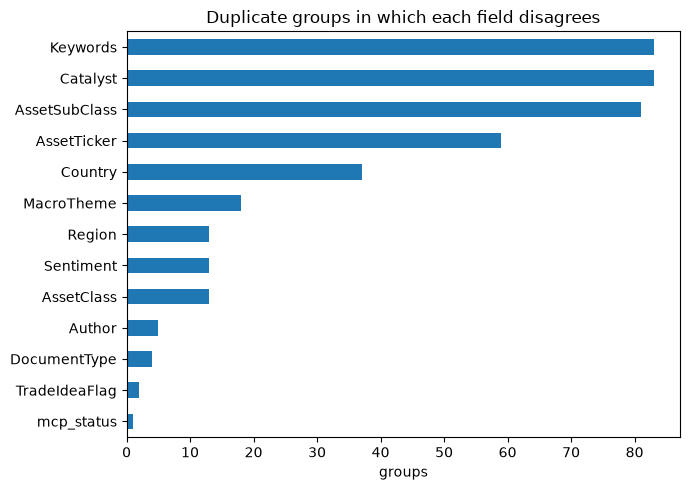

In [3]:
ax = per_field[per_field > 0].sort_values().plot.barh(figsize=(7, 5))
ax.set_title('Duplicate groups in which each field disagrees')
ax.set_xlabel('groups')
plt.tight_layout()
plt.show()

### Example: one group side by side

Group 4 is the same BNP Europe note filed twice. Its two copies disagree on `DocumentType` and `Country`.

In [4]:
def show_group(gid, fields=None, width=90):
    g = copies[copies['group_id'] == gid]
    cols = fields or diff_by_group[gid]
    view = g.set_index('file_path')[cols]
    return view.apply(lambda col: col.str.slice(0, width)).T

show_group(4, ['DocumentType', 'Country', 'TradeIdeaFlag', 'Author'])

file_path
DocumentType
Country
TradeIdeaFlag
Author


### Classification fields

`DocumentType`, `TradeIdeaFlag`, `Author` and `mcp_status` drive filtering and reporting, so a disagreement here changes results. The other fields are mostly extracted per chunk and are expected to vary more.

In [5]:
CLASS_FIELDS = ['DocumentType', 'TradeIdeaFlag', 'Author', 'mcp_status']
flagged = [gid for gid, d in diff_by_group.items() if set(d) & set(CLASS_FIELDS)]
print(len(flagged), 'groups disagree on a classification field')

for gid in flagged:
    print(f'\n--- group {gid}')
    display(show_group(gid, [f for f in CLASS_FIELDS if f in diff_by_group[gid]], width=60))

11 groups disagree on a classification field

--- group 109


file_path,local/2026-08-31/JPM_Global Markets Strategy - U.S. Fixed Income Markets Weekly.pdf,local/2026-08-31/JPM_U.S. Fixed Income Markets Weekly.pdf
Author,"[{""Name"": ""A Berke"", ""Role"": ""Strategist""}, {""...","[{""Name"": ""Jay Barry"", ""Role"": ""Strategist""}]"



--- group 125


file_path,local/2026-10-23/BC_Interest Rate Derivatives - Swap Spreads - Not spooky enough.pdf,local/2026-10-26/BC_Interest Rate Derivatives - Swap Spreads - Not Spooky Enough.pdf
TradeIdeaFlag,False,True



--- group 28


file_path,local/2025-06-13/2025-06-11 BoJ_Monetary Policy Meeting Preview - Spotlight on QT pace interest rates less important.pdf,local/2025-06-13/2025-06-11 Citi_BoJ Monetary Policy Meeting Preview - Spotlight on QT pace interest rates less important.pdf
TradeIdeaFlag,False,True
Author,"[{""Name"": ""Katsuhiko Aiba"", ""Role"": ""Strategis...","[{""Name"": ""Katsuhiko Aiba"", ""Role"": ""Analyst""}..."


... (12 outputs left out)


--- group 79


file_path,local/2026-04-24/DB_Central Bank Bonanza - Transcript.pdf,local/2026-04-24/DB_Rate Check - Where Macro Meets Markets.pdf
Author,"[{""Name"": ""Henry Allen"", ""Role"": null}, {""Name...","[{""Name"": ""Henry Allen"", ""Role"": ""Strategist""}..."



--- group 94


file_path,"local/2026-06-05/MS_Europe - Euro Area Rates Strategy - Expectations Disappointed, Again.pdf",local/2026-06-05/MS_Government Bond Auctions - The Month Ahead.pdf
mcp_status,matched,matched_ambiguous


### Source vs. filename

Filenames carry a bank or publisher prefix (`BNP_`, `MS_`, `Citi_`, ...). Within a group, copies whose prefixes differ should not share a single `Source` if the prefix is right, so each mismatch below needs checking against the document itself.

In [6]:
copies['filename_prefix'] = copies['file_name'].str.extract(r'^([A-Za-z]+)_')[0].fillna('(none)')

prefix_mixed = [gid for gid, g in copies.groupby('group_id') if g['filename_prefix'].nunique() > 1]
print(len(prefix_mixed), 'groups have filenames with more than one prefix')

copies[copies['group_id'].isin(prefix_mixed)][['group_id', 'file_path', 'filename_prefix', 'Source']]

25 groups have filenames with more than one prefix


,group_id,file_path,filename_prefix,Source
0,1,bnp/China_Stronger-than-expected_Q3_growth_rul...,China,BNP Paribas
1,1,local/2026-10-19/BNP_China - Stronger-than-exp...,BNP,BNP Paribas
2,2,bnp/DM_rates_Enter_long_duration_in_Europe_Tra...,DM,BNP Paribas
3,2,local/2025-01-03/BNP_DM rates - Enter long dur...,BNP,BNP Paribas
4,3,bnp/European_power_and_carbon_update_Summer_ri...,European,
5,3,local/2026-10-16/BNP_European power and carbon...,BNP,
6,4,bnp/Europe_Whatever_it_takes_Desknote--861647.pdf,Europe,BNP Paribas
7,4,local/2025-03-06/BNP_Europe - Whatever it take...,BNP,BNP Paribas
8,5,bnp/FX_Japan_investors_shy_on_shedding_hedging...,FX,BNP Paribas
9,5,local/2025-06-30/BNP_FX - Japan investors shy ...,BNP,BNP Paribas


### Groups with no `Source` on any copy

In [7]:
no_source = [gid for gid, g in copies.groupby('group_id') if (g['Source'] == '').all()]
print(len(no_source), 'groups with no Source')

copies[copies['group_id'].isin(no_source)][['group_id', 'file_path', 'Title']]

5 groups with no Source


,group_id,file_path,Title
4,3,bnp/European_power_and_carbon_update_Summer_ri...,
5,3,local/2026-10-16/BNP_European power and carbon...,
12,7,bnp/Global_Outlook_Q4_2026_Prompted_to_hike_Gl...,
13,7,local/2026-10-09/BNP_Global Outlook q4 2026 - ...,
134,67,local/2026-03-23/UBS_European Economic Perspec...,Eurozone: Energy to push March inflation to 2.6%
135,67,local/2026-03-23/UBS_Eurozone - Energy to push...,Eurozone: Energy to push March inflation to 2.6%
258,129,statestreet/Equity_Market_Insight/d0cc253b-6d2...,
259,129,statestreet/Fixed_Income_and_Currency_Insight/...,
260,130,statestreet/Fixed_Income_and_Currency_Insight/...,
261,130,statestreet/Fixed_Income_and_Currency_Insight/...,


## ledger_v3_matched (mcp_chunk_ids removed) x MCP Alignment

In [61]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

LEDGER_V3 = Path('.') / 'data' / 'corpus' / 'ledger_v3_matched.csv'
ledger = pd.read_csv(LEDGER_V3, dtype=str).fillna('')

In [62]:
ledger.columns

Index(['file_path', 'file_name', 'hash_id', 'Source', 'Author', 'Title',
       'CreationDate', 'DocumentDate', 'Region', 'Country', 'MacroTheme',
       'AssetClass', 'AssetSubClass', 'AssetTicker', 'Keywords', 'Sentiment',
       'Catalyst', 'TradeIdeaFlag', 'mcp_status', 'mcp_note',
       'mcp_ref_chunk_id', 'mcp_missing_chunks', 'redundant_duplicate'],
      dtype='str')

In [36]:
class PdfDateParser:
    """Parses PDF dates: D:YYYYMMDDHHmmSS[Z | ±HH'mm']"""
    FORMAT = "%Y%m%d%H%M%S%z"

    def parse(self, s: pd.Series) -> pd.Series:
        return pd.to_datetime(self._normalise(s), format=self.FORMAT,
                              utc=True, errors="coerce")

    def _normalise(self, s: pd.Series) -> pd.Series:
        return (s.str.removeprefix("D:")
                 .str.replace("Z", "+0000", regex=False)
                 .str.replace("'", "", regex=False))


class UTCDatetimeParser(PdfDateParser):
    """UTC clock times with no timezone label (no +00:00)."""
    def parse(self, s: pd.Series) -> pd.Series:
        return super().parse(s).dt.tz_localize(None)

class UTCDateParser(UTCDatetimeParser):
    """UTC date only, time stripped."""
    def parse(self, s: pd.Series) -> pd.Series:
        return super().parse(s).dt.normalize()
    
class LocalPdfDateParser(PdfDateParser):
    """Same parsing, but returns a chosen timezone instead of UTC."""
    def __init__(self, tz="Europe/London"):
        self.tz = tz

    def parse(self, s: pd.Series) -> pd.Series:
        return super().parse(s).dt.tz_convert(self.tz)

In [48]:
ledger["CreationDate"] = UTCDateParser().parse(ledger["CreationDate"])

In [57]:
# ledger.drop(columns=["created_at", "doc_date"], inplace=True)
ledger.columns

Index(['file_path', 'file_name', 'Source', 'Author', 'Title', 'CreationDate',
       'DocumentDate', 'Region', 'Country', 'MacroTheme', 'AssetClass',
       'AssetSubClass', 'AssetTicker', 'Keywords', 'Sentiment', 'Catalyst',
       'TradeIdeaFlag', 'DocumentType', 'mcp_status', 'mcp_note',
       'mcp_n_chunks', 'mcp_ref_chunk_id', 'mcp_missing_chunks'],
      dtype='str')

In [58]:
ledger.drop(columns=["mcp_n_chunks", "DocumentType"], inplace=True)

In [59]:
ledger.columns

Index(['file_path', 'file_name', 'Source', 'Author', 'Title', 'CreationDate',
       'DocumentDate', 'Region', 'Country', 'MacroTheme', 'AssetClass',
       'AssetSubClass', 'AssetTicker', 'Keywords', 'Sentiment', 'Catalyst',
       'TradeIdeaFlag', 'mcp_status', 'mcp_note', 'mcp_ref_chunk_id',
       'mcp_missing_chunks'],
      dtype='str')

In [60]:
ledger.to_csv(LEDGER_V3, index=False)

## ledger_v3_matched x Final check

In [63]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

LEDGER_V3 = Path('.') / 'data' / 'corpus' / 'ledger_v3_matched.csv'
ledger = pd.read_csv(LEDGER_V3, dtype=str).fillna('')

In [68]:
ledger['file_name'].head(1)

0    2025_EUR_government_bond_and_SSA_issuance_outl...
Name: file_name, dtype: str